In [1]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde

In [4]:
#Defining all the required functions

#Fourier Transform Functions
def partial_x_fft(f, dx):
    nx, ny = f.shape
    kx = 2 * np.pi * np.fft.fftfreq(nx, d=dx)
    f_fft = np.fft.fft(f, axis=0)
    df_fft = 1j * kx[:, None] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=0))

def partial_y_fft(f, dy):
    nx, ny = f.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny, d=dy)
    f_fft = np.fft.fft(f, axis=1)
    df_fft = 1j * ky[None, :] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=1))

#Defining constants
dx = 0.0625
dy = 0.0625

def iterative_filtering1D(field, index, Xi=1.6):
    fif = fifpy.MIF(NIMFs=4,alpha=30,Xi=Xi)
    fif.run(field)
    print(fif.IMC.shape)
    filtered_signal = np.sum(fif.IMC[index:],axis=0)
    return filtered_signal

def iterative_filtering3D(fieldX, fieldY, fieldZ, index, Xi=1.6):
    fif = fifpy.MIF(NIMFs=4,alpha=30, Xi=Xi)
    fif.run(fieldX)
    mif_x = fif.IMC
    logm = np.array([fif.data['stats_list']['logMx'],fif.data['stats_list']['logMy']]).min(axis=0)
    fif.run(fieldY, M=logm)
    mif_y = fif.IMC
    fif.run(fieldZ, M=logm)
    mif_z = fif.IMC
    filtered_x = np.sum(mif_x[index:], axis=0)
    filtered_y = np.sum(mif_y[index:], axis=0)
    filtered_z = np.sum(mif_z[index:], axis=0)
    return filtered_x, filtered_y, filtered_z

def detect_current_sheets(mod_Jz):

    J2_rms = np.mean(mod_Jz)
    
    # size of grid
    nx, ny = mod_Jz.shape
    
    # global maximum |Jz|
    max_global = np.max(mod_Jz)
    
    # threshold to stop searching for new sheets
    # global_threshold = 0.1 * max_global
    global_threshold = 10 * J2_rms
    
    # keep track of points already assigned to sheets
    visited = np.zeros_like(mod_Jz, dtype=bool)
    
    # list to store all current sheets
    current_sheets = []

    while True:
        
        # mask out already visited cells
        masked_field = np.where(visited, -np.inf, mod_Jz)
        
        # location of largest remaining |Jz|
        max_index = np.unravel_index(np.argmax(masked_field), mod_Jz.shape)
        peak_value = mod_Jz[max_index]
        
        # stop condition
        if peak_value < global_threshold:
            break
        
        # threshold for this sheet
        local_threshold = 0.5 * peak_value
        
        # stack for depth-first search
        stack = [max_index]
        
        # store indices belonging to this sheet
        sheet_points = []
        
        while stack:
            
            i, j = stack.pop()
            
            if visited[i, j]:
                continue
            
            if mod_Jz[i, j] <= local_threshold:
                continue
            
            visited[i, j] = True
            sheet_points.append((i, j))
            
            # check 4 neighbors
            neighbors = [
                (i+1, j),
                (i-1, j),
                (i, j+1),
                (i, j-1)
            ]
            
            for ni, nj in neighbors:
                if 0 <= ni < nx and 0 <= nj < ny:
                    if not visited[ni, nj]:
                        stack.append((ni, nj))
        
        current_sheets.append(sheet_points)

    return current_sheets


--- Processing beta = 0.0625 ---
Loading cached filtered fields...

--- Processing beta = 1 ---
Loading cached filtered fields...

--- Processing beta = 16 ---
Loading cached filtered fields...


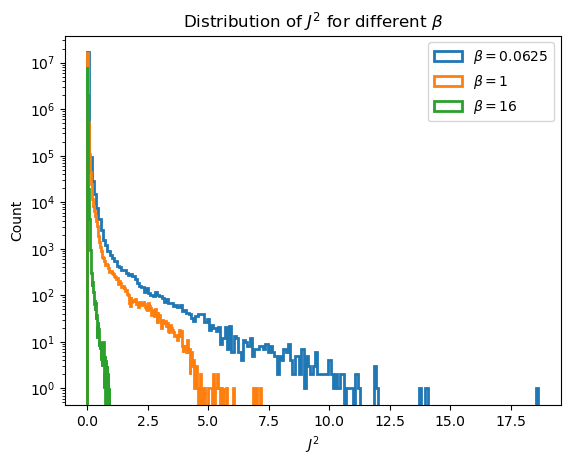

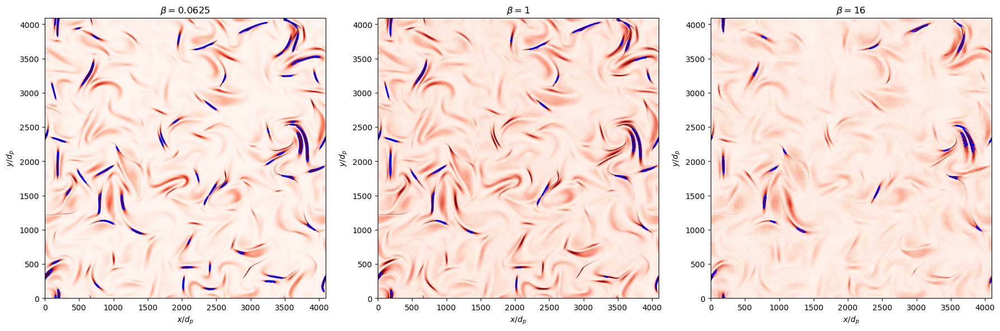

In [5]:
# -----------------------------
# USER SETTINGS
# -----------------------------
betas = [0.0625, 1, 16]

cache_dir = "filtered_cache"
os.makedirs(cache_dir, exist_ok=True)

# storage
J2_all = {}
mask_all = {}

# -----------------------------
# MAIN LOOP
# -----------------------------
for beta in betas:

    print(f"\n--- Processing beta = {beta} ---")

    # ----- FILE PATH -----
    base_path = f'/home/UNN/w24021992/NAS/simulations_beta_scan/beta_p_{beta}/beta_e_1/'

    File_Bx = base_path + 'Bx_ApJ_t40.h5'
    File_By = base_path + 'By_ApJ_t40.h5'
    File_Bz = base_path + 'Bz_ApJ_t40.h5'

    with h5py.File(File_Bx, 'r') as fBx, \
         h5py.File(File_By, 'r') as fBy, \
         h5py.File(File_Bz, 'r') as fBz:

        data_Bx = fBx['DS1'][:].T
        data_By = fBy['DS1'][:].T
        data_Bz = fBz['DS1'][:].T

    # ----- FILTER PARAMETERS -----
    if beta == 0.0625:
        n_iter, Xi = 1, 1.6
    elif beta == 1:
        n_iter, Xi = 2, 2.0
    else:
        n_iter, Xi = 3, 2.0

    cache_file = f"{cache_dir}/filtered_beta_{beta}_iter{n_iter}_Xi{Xi}.npz"

    # ----- LOAD OR COMPUTE FILTERED FIELDS -----
    if os.path.exists(cache_file):
        print("Loading cached filtered fields...")
        data = np.load(cache_file)
        data_Bx_f = data['Bx']
        data_By_f = data['By']
        data_Bz_f = data['Bz']

    else:
        print("Computing filtering (slow)...")

        data_Bx_f, data_By_f, data_Bz_f = iterative_filtering3D(
            data_Bx, data_By, data_Bz, n_iter, Xi=Xi
        )

        np.savez_compressed(
            cache_file,
            Bx=data_Bx_f,
            By=data_By_f,
            Bz=data_Bz_f
        )

    # ----- CURRENT DENSITY -----
    Jx = partial_y_fft(data_Bz_f, dx)
    Jy = -partial_x_fft(data_Bz_f, dy)
    Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)

    J2 = Jx**2 + Jy**2 + Jz**2
    
    # J2_norm = J2 / np.mean(J2)
    # J2 = J2_norm

    plt.hist(J2.ravel(), bins=200, log=True,
         histtype='step', linewidth=2,
         label=fr'$\beta = {beta}$')
    
    # ----- CURRENT SHEET DETECTION -----
    sheets = detect_current_sheets(J2)

    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1

    # ----- MORPHOLOGICAL CLEANING -----
    struct = morphology.disk(5)

    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    mask = morphology.remove_small_objects(
        mask.astype(bool), min_size=500
    ).astype(int)

    # store
    J2_all[beta] = J2
    mask_all[beta] = mask

plt.legend()
plt.xlabel(r'$J^2$')
plt.ylabel('Count')
plt.title(r'Distribution of $J^2$ for different $\beta$')
plt.show()

# -----------------------------
# GLOBAL COLOR SCALE
# -----------------------------
all_values = np.concatenate([J2_all[b].ravel() for b in betas])
vmax_global = np.percentile(all_values, 99)

# -----------------------------
# SIDE-BY-SIDE PLOT
# -----------------------------
fig, axes = plt.subplots(1, len(betas), figsize=(6 * len(betas), 6))

if len(betas) == 1:
    axes = [axes]

for ax, beta in zip(axes, betas):
    im = ax.imshow(
        J2_all[beta].T,
        cmap='Reds',
        origin='lower',
        vmax=vmax_global
    )

    ax.contour(
        mask_all[beta].T,
        levels=[0.5],
        colors='blue',
        linewidths=1
    )

    ax.set_title(fr'$\beta = {beta}$')
    ax.set_xlabel(r'$x/d_p$')
    ax.set_ylabel(r'$y/d_p$')

# shared colorbar
# fig.colorbar(im, ax=axes, shrink=0.8)

plt.tight_layout()
plt.savefig("J2_comparison_all_betas.png", dpi=300)
plt.show()

[beta=0.0625] Regions found: 72
[beta=0.0625] (M1) regions: 72
[beta=0.0625] M1 mean=41.072, median=34.928, min=14.000, max=112.588
[beta=0.0625] M2 mean=35.361, median=26.000, min=7.000, max=194.000
[beta=0.0625] M3 mean=15.316, median=12.678, min=1.915, max=48.824
[beta=1] Regions found: 97
[beta=1] (M1) regions: 97
[beta=1] M1 mean=32.788, median=31.241, min=13.416, max=84.214
[beta=1] M2 mean=38.856, median=28.000, min=1.000, max=204.000
[beta=1] M3 mean=22.250, median=16.986, min=2.826, max=92.952
[beta=16] Regions found: 57
[beta=16] (M1) regions: 57
[beta=16] M1 mean=48.203, median=50.000, min=12.649, max=108.812
[beta=16] M2 mean=60.105, median=41.000, min=5.000, max=380.000
[beta=16] M3 mean=26.013, median=26.457, min=3.192, max=80.379


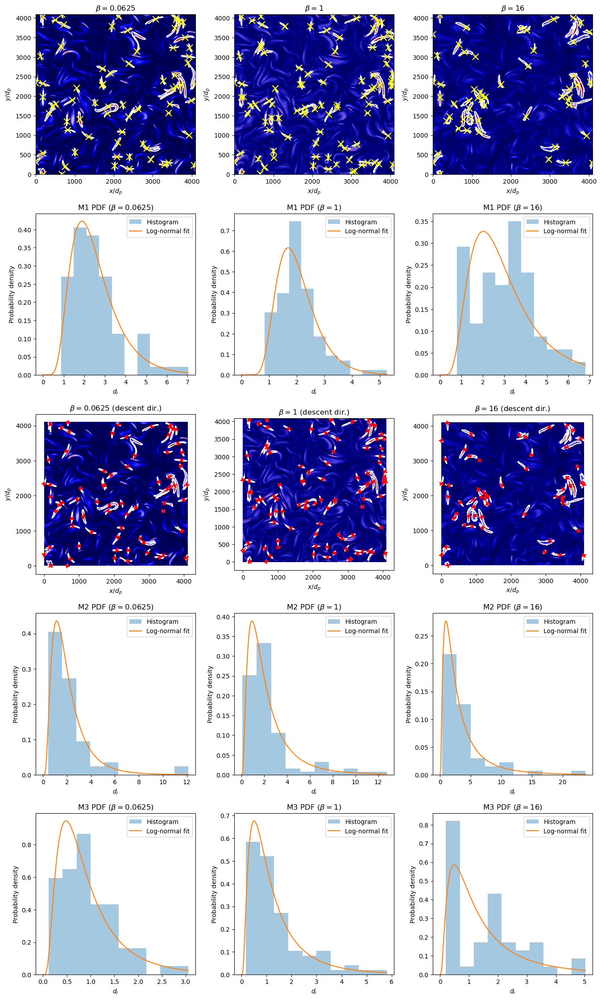

In [6]:
# ---------- Gaussian model for M3 ----------
def gaussian(t, A, mu, sigma, B):
    return A * np.exp(-(t - mu)**2 / (2*sigma**2)) + B

# ---------- M3 sampling parameters ----------
max_len = 60   # half-length of profile (pixels)
step_px = 1    # pixel step along line

# ---------- Parent folder for M3 Gaussian fits ----------
parent_save_folder = "gaussian_fits_J2_NR"
os.makedirs(parent_save_folder, exist_ok=True)

# ---------- Figure setup: 5 rows x len(betas) cols ----------
fig, axes = plt.subplots(5, len(betas), figsize=(4.5*len(betas), 22.5))

# Guard against single-beta case so indexing stays consistent
if len(betas) == 1:
    axes = axes.reshape(5, 1)

for idx, beta in enumerate(betas):
    ax_img_m1  = axes[0, idx]
    ax_hist_m1 = axes[1, idx]
    ax_img_m2  = axes[2, idx]
    ax_hist_m2 = axes[3, idx]
    ax_hist_m3 = axes[4, idx]

    cleaned_mask = mask_all[beta]
    J2 = J2_all[beta]

    # -----------------------------
    # CONNECTED REGIONS (for maxima)
    # -----------------------------
    labeled_mask, num_features = label(cleaned_mask)
    print(f"[beta={beta}] Regions found:", num_features)

    max_coords = []
    max_values = []

    for i in range(1, num_features + 1):
        region_mask = (labeled_mask == i)
        region_vals = J2[region_mask]

        if region_vals.size == 0:
            continue

        max_pos = np.argmax(np.abs(region_vals))
        extreme_value = region_vals[max_pos]
        max_values.append(extreme_value)

        xs_r, ys_r = np.where(region_mask)
        max_coords.append((xs_r[max_pos], ys_r[max_pos]))

    boundaries = find_boundaries(labeled_mask)

    # -----------------------------
    # ROW 0: FIELD + MAXIMA (for M1 context)
    # -----------------------------
    ax_img_m1.imshow(J2.T, cmap='seismic', origin='lower', vmax=vmax_global)
    ax_img_m1.contour(boundaries.T, levels=[0.5], colors='white', linewidths=1)
    for x, y in max_coords:
        ax_img_m1.plot(x, y, marker='x', markersize=10,
                       markeredgewidth=1.5, color='yellow')
    ax_img_m1.set_title(rf'$\beta = {beta}$')
    ax_img_m1.set_xlabel(r'$x/d_p$')
    ax_img_m1.set_ylabel(r'$y/d_p$')

    # -----------------------------
    # METHOD 1 THICKNESS (distance transform)
    # -----------------------------
    labeled_mask_m1 = measure.label(cleaned_mask, connectivity=2)
    num_regions = labeled_mask_m1.max()
    print(f"[beta={beta}] (M1) regions:", num_regions)

    thicknesses_m1 = []
    for label_id in range(1, num_regions + 1):
        region = (labeled_mask_m1 == label_id)
        dist = ndi.distance_transform_edt(region)
        thicknesses_m1.append(2 * dist.max())

    print(f"[beta={beta}] M1 mean={np.mean(thicknesses_m1):.3f}, "
          f"median={np.median(thicknesses_m1):.3f}, "
          f"min={np.min(thicknesses_m1):.3f}, max={np.max(thicknesses_m1):.3f}")

    # -----------------------------
    # ROW 1: M1 PDF + LOGNORMAL FIT
    # -----------------------------
    x_m1 = np.array(thicknesses_m1)
    x_m1 = x_m1[x_m1 > 0]
    x_m1_di = x_m1 / 16.0

    shape_m1, loc_m1, scale_m1 = lognorm.fit(x_m1_di, floc=0)
    xs_fit_m1 = np.linspace(0, x_m1_di.max(), 300)

    ax_hist_m1.hist(x_m1_di, bins=10, density=True, alpha=0.4, label="Histogram")
    ax_hist_m1.plot(xs_fit_m1,
                    lognorm.pdf(xs_fit_m1, shape_m1, loc_m1, scale_m1),
                    label="Log-normal fit")
    ax_hist_m1.set_xlabel(r"$d_i$")
    ax_hist_m1.set_ylabel("Probability density")
    ax_hist_m1.set_title(rf'M1 PDF ($\beta = {beta}$)')
    ax_hist_m1.legend()

    # -----------------------------
    # METHOD 2: STEEPEST-DESCENT DIRECTIONS
    # -----------------------------
    # Gradient of smoothed field
    sigma=3
    J2_smooth = gaussian_filter(J2, sigma=sigma)
    dJdx, dJdy = np.gradient(J2_smooth)

    descent_dirs = []
    for (x, y) in max_coords:
        grad = np.array([dJdx[x, y], dJdy[x, y]])
        if np.allclose(grad, 0):
            descent_dirs.append(np.array([0.0, 0.0]))
        else:
            descent_dirs.append(-grad / np.linalg.norm(grad))

    # -----------------------------
    # ROW 2: FIELD + DESCENT ARROWS
    # -----------------------------
    ax_img_m2.imshow(J2.T, cmap='seismic', origin='lower',
                     vmax=vmax_global, aspect='equal', zorder=0)
    ax_img_m2.contour(boundaries.T, levels=[0.5], colors='white',
                      linewidths=1, zorder=2)

    factor = 200.0
    for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
        start = (x - 0.5 * factor * dx, y - 0.5 * factor * dy)
        end   = (x + 0.5 * factor * dx, y + 0.5 * factor * dy)
        arrow = FancyArrowPatch(start, end, arrowstyle="<->",
                                color="red", mutation_scale=10,
                                linewidth=2, zorder=10)
        ax_img_m2.add_patch(arrow)

    ax_img_m2.set_title(rf'$\beta = {beta}$ (descent dir.)')
    ax_img_m2.set_xlabel(r'$x/d_p$')
    ax_img_m2.set_ylabel(r'$y/d_p$')

    # -----------------------------
    # METHOD 2 THICKNESS (walk along descent dir.)
    # -----------------------------
    distances = []
    step_size = 1
    max_steps = 1000

    for (x0, y0), (dx, dy) in zip(max_coords, descent_dirs):
        x0f, y0f = float(x0), float(y0)

        # Forward
        xf, yf = x0f, y0f
        steps = 0
        while steps < max_steps:
            xf_new = xf + dx * step_size
            yf_new = yf + dy * step_size
            xi, yi = int(round(xf_new)), int(round(yf_new))
            if (xi < 0 or yi < 0 or
                xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
                break
            if not cleaned_mask[xi, yi]:
                break
            xf, yf = xf_new, yf_new
            steps += 1
        dist_forward = np.hypot(xf - x0f, yf - y0f)

        # Backward
        xb, yb = x0f, y0f
        steps = 0
        while steps < max_steps:
            xb_new = xb - dx * step_size
            yb_new = yb - dy * step_size
            xi, yi = int(round(xb_new)), int(round(yb_new))
            if (xi < 0 or yi < 0 or
                xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
                break
            if not cleaned_mask[xi, yi]:
                break
            xb, yb = xb_new, yb_new
            steps += 1
        dist_backward = np.hypot(xb - x0f, yb - y0f)

        distances.append((dist_backward, dist_forward))

    thicknesses_m2 = np.array([d[0] + d[1] for d in distances])
    thicknesses_m2 = thicknesses_m2[thicknesses_m2 > 0]

    print(f"[beta={beta}] M2 mean={np.mean(thicknesses_m2):.3f}, "
          f"median={np.median(thicknesses_m2):.3f}, "
          f"min={np.min(thicknesses_m2):.3f}, max={np.max(thicknesses_m2):.3f}")

    # -----------------------------
    # ROW 3: M2 PDF + LOGNORMAL FIT
    # -----------------------------
    x_m2_di = thicknesses_m2 / 16.0
    x_m2_di = x_m2_di[x_m2_di > 0]

    shape_m2, loc_m2, scale_m2 = lognorm.fit(x_m2_di, floc=0)
    xs_fit_m2 = np.linspace(0, x_m2_di.max(), 300)

    ax_hist_m2.hist(x_m2_di, bins=10, density=True, alpha=0.4, label="Histogram")
    ax_hist_m2.plot(xs_fit_m2,
                    lognorm.pdf(xs_fit_m2, shape_m2, loc_m2, scale_m2),
                    label="Log-normal fit")
    ax_hist_m2.set_xlabel(r"$d_i$")
    ax_hist_m2.set_ylabel("Probability density")
    ax_hist_m2.set_title(rf'M2 PDF ($\beta = {beta}$)')
    ax_hist_m2.legend()

    # -----------------------------
    # METHOD 3: FWHM via Gaussian fit along descent direction
    # -----------------------------
    fwhms = []
    xs_list = []
    vals_list = []
    popts_list = []

    for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
        if dx == 0 and dy == 0:
            fwhms.append(np.nan)
            xs_list.append(np.array([]))
            vals_list.append(np.array([]))
            popts_list.append([np.nan]*4)
            continue

        xs, vals = [], []
        for k in range(-max_len, max_len + 1):
            xc = x + k * dx
            yc = y + k * dy
            xi, yi = int(round(xc)), int(round(yc))
            if 0 <= xi < J2.shape[0] and 0 <= yi < J2.shape[1]:
                xs.append(k)
                vals.append(J2[xi, yi])

        xs = np.array(xs)
        vals = np.array(vals)
        xs_list.append(xs)
        vals_list.append(vals)

        if len(vals) < 3:
            fwhms.append(np.nan)
            popts_list.append([np.nan]*4)
            continue

        A0 = vals.max() - vals.min()
        mu0 = xs[np.argmax(vals)]
        sigma0 = max_len / 4
        B0 = vals.min()

        try:
            popt, _ = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0])
            A, mu, sigma_fit, B = popt
            fwhm = 2 * np.sqrt(2 * np.log(2)) * sigma_fit
            fwhms.append(fwhm)
            popts_list.append(popt)
        except RuntimeError:
            fwhms.append(np.nan)
            popts_list.append([np.nan]*4)

    # Save individual Gaussian fits in a per-beta subfolder
    beta_save_folder = os.path.join(parent_save_folder, f"beta_{beta}")
    os.makedirs(beta_save_folder, exist_ok=True)

    for i, (xs, vals, popt, fwhm) in enumerate(zip(xs_list, vals_list, popts_list, fwhms)):
        if len(xs) == 0 or np.isnan(popt[0]):
            continue
        A, mu, sigma_fit, B = popt
        x_dense = np.linspace(xs.min(), xs.max(), 500)
        fit_curve = A * np.exp(-(x_dense - mu)**2 / (2*sigma_fit**2)) + B

        fig_fit, ax_fit = plt.subplots()
        ax_fit.plot(xs, vals, 'o', label="sampled profile")
        ax_fit.plot(x_dense, fit_curve, label="Gaussian fit")
        ax_fit.set_title(f"beta={beta}, sample {i} — FWHM = {fwhm:.2f} px")
        ax_fit.set_xlabel("t (pixels)")
        ax_fit.set_ylabel("Intensity")
        ax_fit.legend()
        fig_fit.savefig(os.path.join(beta_save_folder, f"fit_{i:03d}.png"))
        plt.close(fig_fit)

    # Filter FWHMs
    fwhms_array = np.array(fwhms)
    thicknesses_m3 = fwhms_array[~np.isnan(fwhms_array)]
    thicknesses_m3 = thicknesses_m3[(thicknesses_m3 > 0) & (thicknesses_m3 <= 100)]

    print(f"[beta={beta}] M3 mean={np.mean(thicknesses_m3):.3f}, "
          f"median={np.median(thicknesses_m3):.3f}, "
          f"min={np.min(thicknesses_m3):.3f}, max={np.max(thicknesses_m3):.3f}")

    # -----------------------------
    # ROW 4: M3 PDF + LOGNORMAL FIT
    # -----------------------------
    x_m3_di = thicknesses_m3 / 16.0

    if x_m3_di.size > 0:
        shape_m3, loc_m3, scale_m3 = lognorm.fit(x_m3_di, floc=0)
        xs_fit_m3 = np.linspace(0, x_m3_di.max(), 300)

        ax_hist_m3.hist(x_m3_di, bins=10, density=True, alpha=0.4, label="Histogram")
        ax_hist_m3.plot(xs_fit_m3,
                        lognorm.pdf(xs_fit_m3, shape_m3, loc_m3, scale_m3),
                        label="Log-normal fit")
        ax_hist_m3.legend()

    ax_hist_m3.set_xlabel(r"$d_i$")
    ax_hist_m3.set_ylabel("Probability density")
    ax_hist_m3.set_title(rf'M3 PDF ($\beta = {beta}$)')

plt.tight_layout()
plt.savefig("J2_NR_M1_M2_M3_combined.png", dpi=300)
plt.show()

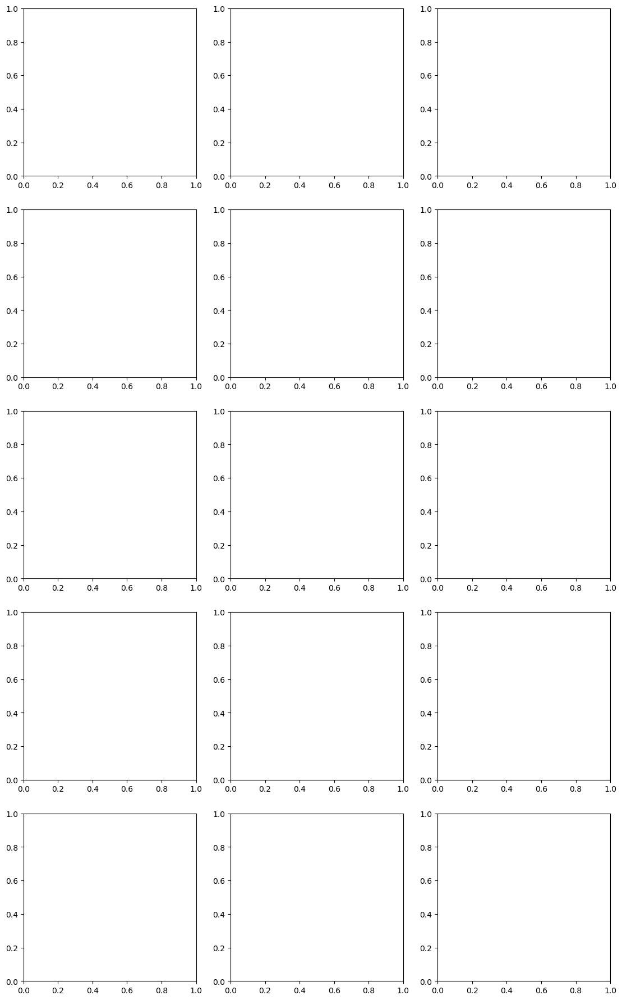

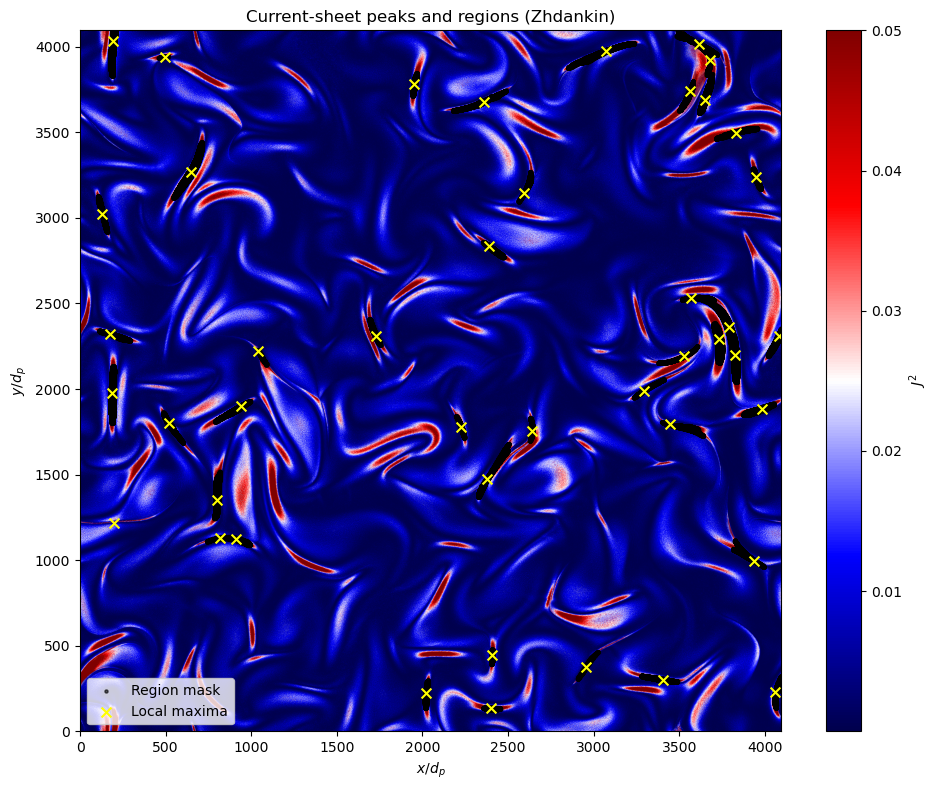

[beta=0.0625] Regions found: 48 | maxima: 44
[beta=0.0625] (M1) regions: 44
[beta=0.0625] M1 mean=17.222, median=16.062, min=4.472, max=35.777
[beta=0.0625] M2 mean=27.744, median=14.000, min=4.000, max=289.000
[beta=0.0625] M3 mean=12.881, median=10.539, min=1.430, max=82.043
[beta=1] Regions found: 252 | maxima: 69
[beta=1] (M1) regions: 200


In [ ]:
# =============================================================
# Zhdankin-style detection — replaces the precomputed mask_all
# =============================================================
def detect_sheets_zhdankin(J2,
                           n=50,
                           peak_factor=3.0,
                           region_factor=0.005,
                           morph_radius=2,
                           wrap=True,
                           plot=False,
                           plot_path=None):
    """
    Returns
    -------
    cleaned_mask : 2D bool ndarray
    max_coords   : list of (x, y) tuples, axis-0/axis-1 order
    """
    J2_rms = np.sqrt(np.mean(J2**2))
    thresh_peak   = peak_factor   * J2_rms
    thresh_region = region_factor * np.max(J2)

    # Step 1 — local maxima above peak threshold
    mode = 'wrap' if wrap else 'nearest'
    local_max = maximum_filter(J2, size=(2*n + 1), mode=mode)
    maxima_mask = (J2 == local_max) & (J2 > thresh_peak)

    # Step 2 — grow connected regions around those maxima
    above_thresh = np.abs(J2) > thresh_region
    labeled_regions, _ = label(above_thresh, structure=np.ones((3, 3)))
    keep_labels = np.unique(labeled_regions[maxima_mask])
    keep_labels = keep_labels[keep_labels > 0]
    region_mask = np.isin(labeled_regions, keep_labels)

    # Step 3 — morphological smoothing
    struct = morphology.disk(morph_radius)
    cleaned_mask = morphology.binary_opening(region_mask, struct)
    cleaned_mask = morphology.binary_closing(cleaned_mask, struct)

    xs_max, ys_max = np.where(maxima_mask)
    max_coords = list(zip(xs_max.tolist(), ys_max.tolist()))

    if plot:
        fig, ax = plt.subplots(figsize=(10, 8))
        img = ax.imshow(J2.T, cmap='seismic', vmax=0.05, origin='lower')
        plt.colorbar(img, ax=ax, label=r'$J^2$')
        x_reg, y_reg = np.where(cleaned_mask)
        ax.scatter(x_reg, y_reg, s=5, color='black', alpha=0.6, label='Region mask')
        ax.scatter(xs_max, ys_max, marker='x', color='yellow', s=50, label='Local maxima')
        ax.set_title(r'Current-sheet peaks and regions (Zhdankin)')
        ax.set_xlabel(r'$x/d_{p}$')
        ax.set_ylabel(r'$y/d_{p}$')
        ax.legend()
        plt.tight_layout()
        if plot_path is not None:
            plt.savefig(plot_path, dpi=300)
        plt.show()

    return cleaned_mask, max_coords


# ---------- Gaussian model for M3 ----------
def gaussian(t, A, mu, sigma, B):
    return A * np.exp(-(t - mu)**2 / (2*sigma**2)) + B

# ---------- M3 sampling parameters ----------
max_len = 60
step_px = 1

# ---------- Folders ----------
parent_save_folder = "gaussian_fits_J2_NR_zhdankin"
os.makedirs(parent_save_folder, exist_ok=True)

# ---------- Figure setup ----------
fig, axes = plt.subplots(5, len(betas), figsize=(4.5*len(betas), 22.5))
if len(betas) == 1:
    axes = axes.reshape(5, 1)


for idx, beta in enumerate(betas):
    ax_img_m1  = axes[0, idx]
    ax_hist_m1 = axes[1, idx]
    ax_img_m2  = axes[2, idx]
    ax_hist_m2 = axes[3, idx]
    ax_hist_m3 = axes[4, idx]

    J2 = J2_all[beta]

    # -----------------------------
    # DETECTION (Zhdankin) — diagnostic plot only for the first beta
    # -----------------------------
    run_diag = (idx == 0)
    cleaned_mask, max_coords = detect_sheets_zhdankin(
        J2,
        n=50,
        peak_factor=3.0,
        region_factor=0.005,
        morph_radius=2,
        wrap=True,
        plot=run_diag,
        plot_path=f"J2_NR_M4_diag_beta{beta}.png" if run_diag else None,
    )

    labeled_mask, num_features = label(cleaned_mask)
    print(f"[beta={beta}] Regions found:", num_features, f"| maxima: {len(max_coords)}")

    boundaries = find_boundaries(labeled_mask)

    # -----------------------------
    # ROW 0: FIELD + MAXIMA (M1 context)
    # -----------------------------
    ax_img_m1.imshow(J2.T, cmap='seismic', origin='lower', vmax=vmax_global)
    ax_img_m1.contour(boundaries.T, levels=[0.5], colors='white', linewidths=1)
    for x, y in max_coords:
        ax_img_m1.plot(x, y, marker='x', markersize=10,
                       markeredgewidth=1.5, color='yellow')
    ax_img_m1.set_title(rf'$\beta = {beta}$')
    ax_img_m1.set_xlabel(r'$x/d_p$')
    ax_img_m1.set_ylabel(r'$y/d_p$')

    # -----------------------------
    # METHOD 1 — distance transform (per region, independent of max_coords)
    # -----------------------------
    labeled_mask_m1 = measure.label(cleaned_mask, connectivity=2)
    num_regions = labeled_mask_m1.max()
    print(f"[beta={beta}] (M1) regions:", num_regions)

    thicknesses_m1 = []
    for label_id in range(1, num_regions + 1):
        region = (labeled_mask_m1 == label_id)
        dist = ndi.distance_transform_edt(region)
        thicknesses_m1.append(2 * dist.max())

    if thicknesses_m1:
        print(f"[beta={beta}] M1 mean={np.mean(thicknesses_m1):.3f}, "
              f"median={np.median(thicknesses_m1):.3f}, "
              f"min={np.min(thicknesses_m1):.3f}, max={np.max(thicknesses_m1):.3f}")

    # ---------- ROW 1: M1 PDF ----------
    x_m1_di = np.array(thicknesses_m1)
    x_m1_di = x_m1_di[x_m1_di > 0] / 16.0

    if x_m1_di.size > 0:
        shape_m1, loc_m1, scale_m1 = lognorm.fit(x_m1_di, floc=0)
        xs_fit_m1 = np.linspace(0, x_m1_di.max(), 300)
        ax_hist_m1.hist(x_m1_di, bins=10, density=True, alpha=0.4, label="Histogram")
        ax_hist_m1.plot(xs_fit_m1,
                        lognorm.pdf(xs_fit_m1, shape_m1, loc_m1, scale_m1),
                        label="Log-normal fit")
        ax_hist_m1.legend()
    ax_hist_m1.set_xlabel(r"$d_i$")
    ax_hist_m1.set_ylabel("Probability density")
    ax_hist_m1.set_title(rf'M1 PDF ($\beta = {beta}$)')

    # -----------------------------
    # METHOD 2 — steepest-descent walk
    # -----------------------------
    sigma = 3
    J2_smooth = gaussian_filter(J2, sigma=sigma)
    dJdx, dJdy = np.gradient(J2_smooth)

    descent_dirs = []
    for (x, y) in max_coords:
        grad = np.array([dJdx[x, y], dJdy[x, y]])
        if np.allclose(grad, 0):
            descent_dirs.append(np.array([0.0, 0.0]))
        else:
            descent_dirs.append(-grad / np.linalg.norm(grad))

    # ---------- ROW 2: field + descent arrows ----------
    ax_img_m2.imshow(J2.T, cmap='seismic', origin='lower',
                     vmax=vmax_global, aspect='equal', zorder=0)
    ax_img_m2.contour(boundaries.T, levels=[0.5], colors='white',
                      linewidths=1, zorder=2)
    factor = 200.0
    for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
        start = (x - 0.5 * factor * dx, y - 0.5 * factor * dy)
        end   = (x + 0.5 * factor * dx, y + 0.5 * factor * dy)
        arrow = FancyArrowPatch(start, end, arrowstyle="<->",
                                color="red", mutation_scale=10,
                                linewidth=2, zorder=10)
        ax_img_m2.add_patch(arrow)
    ax_img_m2.set_title(rf'$\beta = {beta}$ (descent dir.)')
    ax_img_m2.set_xlabel(r'$x/d_p$')
    ax_img_m2.set_ylabel(r'$y/d_p$')

    # ---------- M2 thickness ----------
    distances = []
    step_size = 1
    max_steps = 1000
    for (x0, y0), (dx, dy) in zip(max_coords, descent_dirs):
        x0f, y0f = float(x0), float(y0)

        xf, yf = x0f, y0f
        steps = 0
        while steps < max_steps:
            xf_new = xf + dx * step_size
            yf_new = yf + dy * step_size
            xi, yi = int(round(xf_new)), int(round(yf_new))
            if (xi < 0 or yi < 0 or
                xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
                break
            if not cleaned_mask[xi, yi]:
                break
            xf, yf = xf_new, yf_new
            steps += 1
        dist_forward = np.hypot(xf - x0f, yf - y0f)

        xb, yb = x0f, y0f
        steps = 0
        while steps < max_steps:
            xb_new = xb - dx * step_size
            yb_new = yb - dy * step_size
            xi, yi = int(round(xb_new)), int(round(yb_new))
            if (xi < 0 or yi < 0 or
                xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
                break
            if not cleaned_mask[xi, yi]:
                break
            xb, yb = xb_new, yb_new
            steps += 1
        dist_backward = np.hypot(xb - x0f, yb - y0f)

        distances.append((dist_backward, dist_forward))

    thicknesses_m2 = np.array([d[0] + d[1] for d in distances])
    thicknesses_m2 = thicknesses_m2[thicknesses_m2 > 0]

    if thicknesses_m2.size:
        print(f"[beta={beta}] M2 mean={np.mean(thicknesses_m2):.3f}, "
              f"median={np.median(thicknesses_m2):.3f}, "
              f"min={np.min(thicknesses_m2):.3f}, max={np.max(thicknesses_m2):.3f}")

    # ---------- ROW 3: M2 PDF ----------
    x_m2_di = thicknesses_m2 / 16.0
    x_m2_di = x_m2_di[x_m2_di > 0]
    if x_m2_di.size > 0:
        shape_m2, loc_m2, scale_m2 = lognorm.fit(x_m2_di, floc=0)
        xs_fit_m2 = np.linspace(0, x_m2_di.max(), 300)
        ax_hist_m2.hist(x_m2_di, bins=10, density=True, alpha=0.4, label="Histogram")
        ax_hist_m2.plot(xs_fit_m2,
                        lognorm.pdf(xs_fit_m2, shape_m2, loc_m2, scale_m2),
                        label="Log-normal fit")
        ax_hist_m2.legend()
    ax_hist_m2.set_xlabel(r"$d_i$")
    ax_hist_m2.set_ylabel("Probability density")
    ax_hist_m2.set_title(rf'M2 PDF ($\beta = {beta}$)')

    # -----------------------------
    # METHOD 3 — FWHM via Gaussian fit
    # -----------------------------
    fwhms, xs_list, vals_list, popts_list = [], [], [], []

    for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
        if dx == 0 and dy == 0:
            fwhms.append(np.nan)
            xs_list.append(np.array([]))
            vals_list.append(np.array([]))
            popts_list.append([np.nan]*4)
            continue

        xs, vals = [], []
        for k in range(-max_len, max_len + 1):
            xc = x + k * dx
            yc = y + k * dy
            xi, yi = int(round(xc)), int(round(yc))
            if 0 <= xi < J2.shape[0] and 0 <= yi < J2.shape[1]:
                xs.append(k)
                vals.append(J2[xi, yi])

        xs = np.array(xs); vals = np.array(vals)
        xs_list.append(xs); vals_list.append(vals)

        if len(vals) < 3:
            fwhms.append(np.nan)
            popts_list.append([np.nan]*4)
            continue

        A0 = vals.max() - vals.min()
        mu0 = xs[np.argmax(vals)]
        sigma0 = max_len / 4
        B0 = vals.min()

        try:
            popt, _ = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0])
            A, mu, sigma_fit, B = popt
            fwhms.append(2 * np.sqrt(2 * np.log(2)) * sigma_fit)
            popts_list.append(popt)
        except RuntimeError:
            fwhms.append(np.nan)
            popts_list.append([np.nan]*4)

    # Save individual fits per beta
    beta_save_folder = os.path.join(parent_save_folder, f"beta_{beta}")
    os.makedirs(beta_save_folder, exist_ok=True)
    for i, (xs, vals, popt, fwhm) in enumerate(zip(xs_list, vals_list, popts_list, fwhms)):
        if len(xs) == 0 or np.isnan(popt[0]):
            continue
        A, mu, sigma_fit, B = popt
        x_dense = np.linspace(xs.min(), xs.max(), 500)
        fit_curve = A * np.exp(-(x_dense - mu)**2 / (2*sigma_fit**2)) + B

        fig_fit, ax_fit = plt.subplots()
        ax_fit.plot(xs, vals, 'o', label="sampled profile")
        ax_fit.plot(x_dense, fit_curve, label="Gaussian fit")
        ax_fit.set_title(f"beta={beta}, sample {i} — FWHM = {fwhm:.2f} px")
        ax_fit.set_xlabel("t (pixels)")
        ax_fit.set_ylabel("Intensity")
        ax_fit.legend()
        fig_fit.savefig(os.path.join(beta_save_folder, f"fit_{i:03d}.png"))
        plt.close(fig_fit)

    fwhms_array = np.array(fwhms)
    thicknesses_m3 = fwhms_array[~np.isnan(fwhms_array)]
    thicknesses_m3 = thicknesses_m3[(thicknesses_m3 > 0) & (thicknesses_m3 <= 100)]

    if thicknesses_m3.size:
        print(f"[beta={beta}] M3 mean={np.mean(thicknesses_m3):.3f}, "
              f"median={np.median(thicknesses_m3):.3f}, "
              f"min={np.min(thicknesses_m3):.3f}, max={np.max(thicknesses_m3):.3f}")

    # ---------- ROW 4: M3 PDF ----------
    x_m3_di = thicknesses_m3 / 16.0
    if x_m3_di.size > 0:
        shape_m3, loc_m3, scale_m3 = lognorm.fit(x_m3_di, floc=0)
        xs_fit_m3 = np.linspace(0, x_m3_di.max(), 300)
        ax_hist_m3.hist(x_m3_di, bins=10, density=True, alpha=0.4, label="Histogram")
        ax_hist_m3.plot(xs_fit_m3,
                        lognorm.pdf(xs_fit_m3, shape_m3, loc_m3, scale_m3),
                        label="Log-normal fit")
        ax_hist_m3.legend()
    ax_hist_m3.set_xlabel(r"$d_i$")
    ax_hist_m3.set_ylabel("Probability density")
    ax_hist_m3.set_title(rf'M3 PDF ($\beta = {beta}$)')


plt.tight_layout()
plt.savefig("J2_NR_M1_M2_M3_zhdankin_combined.png", dpi=300)
plt.show()

[beta=0.0625] Regions found: 48 | maxima: 44
[beta=0.0625] (M1) regions: 44
[beta=0.0625] M1 mean=17.222, median=16.062, min=4.472, max=35.777
[beta=0.0625] M2 mean=27.744, median=14.000, min=4.000, max=289.000
[beta=0.0625] M3 mean=12.881, median=10.539, min=1.430, max=82.043
[beta=1] Regions found: 252 | maxima: 69
[beta=1] (M1) regions: 200
[beta=1] M1 mean=11.841, median=5.657, min=4.472, max=49.031
[beta=1] M2 mean=32.435, median=26.000, min=5.000, max=172.000
[beta=1] M3 mean=18.102, median=16.336, min=2.557, max=79.157
[beta=16] Regions found: 5531 | maxima: 436
[beta=16] (M1) regions: 3932
[beta=16] M1 mean=7.031, median=5.657, min=4.472, max=157.747
[beta=16] M2 mean=83.897, median=62.500, min=5.000, max=654.000
[beta=16] M3 mean=19.947, median=6.761, min=2.625, max=94.605


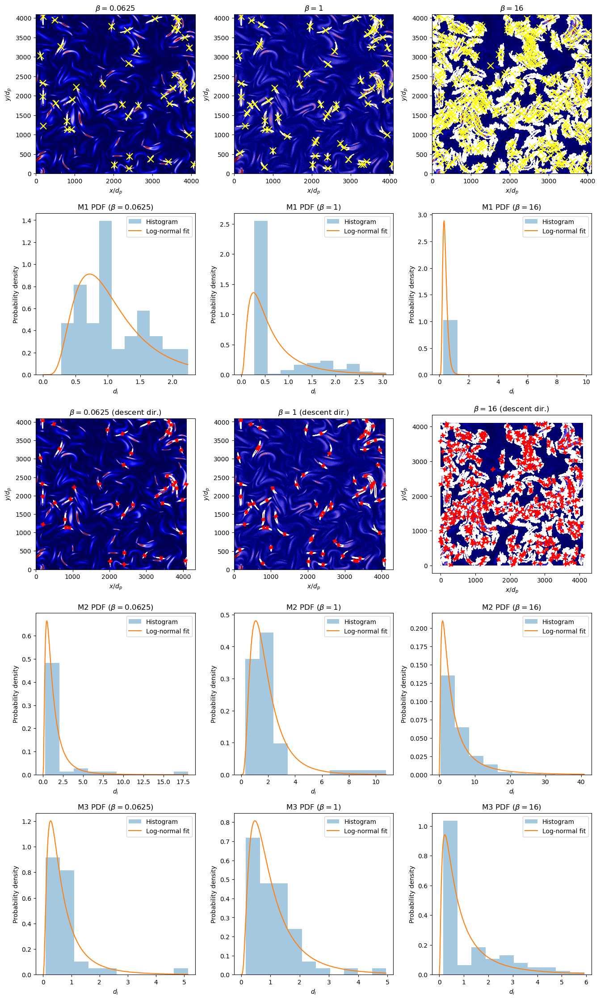

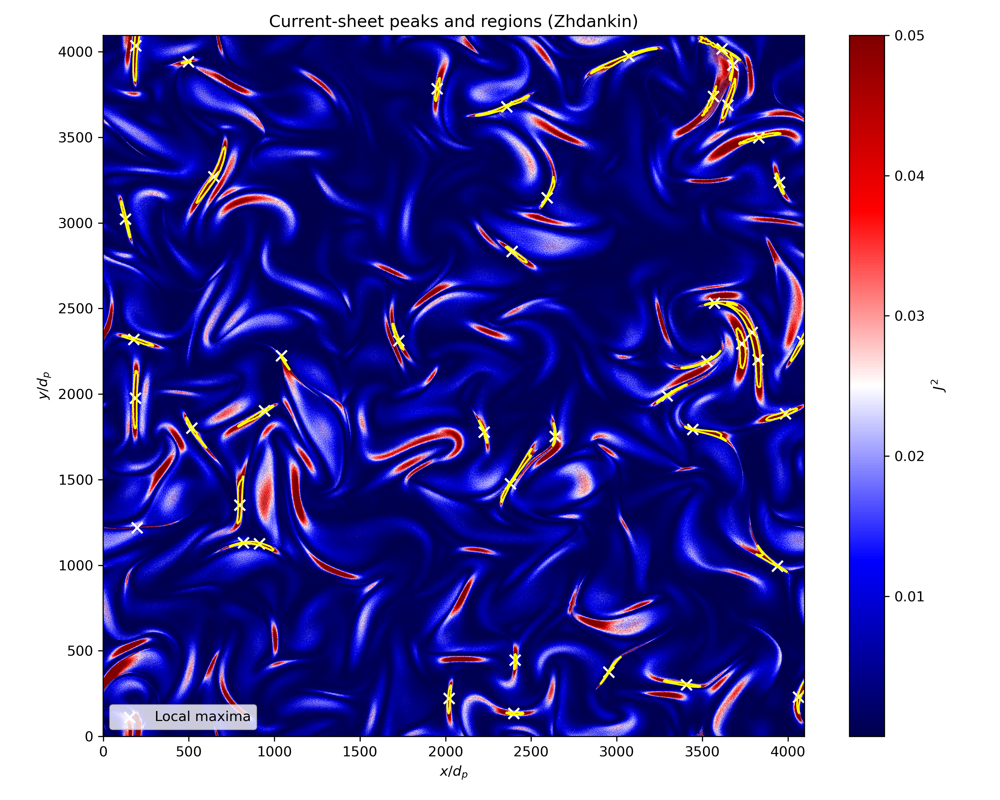

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from scipy.ndimage import label, gaussian_filter, maximum_filter
from scipy import ndimage as ndi
from scipy.stats import lognorm
from scipy.optimize import curve_fit
from skimage import measure, morphology
from skimage.segmentation import find_boundaries


# =============================================================
# Zhdankin-style detection — replaces the precomputed mask_all
# =============================================================
def detect_sheets_zhdankin(J2,
                           n=50,
                           peak_factor=3.0,
                           region_factor=0.005,
                           morph_radius=2,
                           wrap=True,
                           plot=False,
                           plot_path=None):
    """
    Returns
    -------
    cleaned_mask : 2D bool ndarray
    max_coords   : list of (x, y) tuples, axis-0/axis-1 order
    """
    J2_rms = np.sqrt(np.mean(J2**2))
    thresh_peak   = peak_factor   * J2_rms
    thresh_region = region_factor * np.max(J2)

    # Step 1 — local maxima above peak threshold
    mode = 'wrap' if wrap else 'nearest'
    local_max = maximum_filter(J2, size=(2*n + 1), mode=mode)
    maxima_mask = (J2 == local_max) & (J2 > thresh_peak)

    # Step 2 — grow connected regions around those maxima
    above_thresh = np.abs(J2) > thresh_region
    labeled_regions, _ = label(above_thresh, structure=np.ones((3, 3)))
    keep_labels = np.unique(labeled_regions[maxima_mask])
    keep_labels = keep_labels[keep_labels > 0]
    region_mask = np.isin(labeled_regions, keep_labels)

    # Step 3 — morphological smoothing
    struct = morphology.disk(morph_radius)
    cleaned_mask = morphology.binary_opening(region_mask, struct)
    cleaned_mask = morphology.binary_closing(cleaned_mask, struct)

    xs_max, ys_max = np.where(maxima_mask)
    max_coords = list(zip(xs_max.tolist(), ys_max.tolist()))

    if plot:
        fig_diag, ax_diag = plt.subplots(figsize=(10, 8))

        # Background field in seismic with the global vmax
        img = ax_diag.imshow(J2.T, cmap='seismic', vmax=0.05, origin='lower')
        plt.colorbar(img, ax=ax_diag, label=r'$J^2$')

        # Yellow contour around the cleaned region mask
        ax_diag.contour(cleaned_mask.T, levels=[0.5],
                        colors='yellow', linewidths=1.2)

        # White crosses for local maxima
        ax_diag.scatter(xs_max, ys_max,
                        marker='x', color='white', s=60,
                        linewidths=1.5, label='Local maxima')

        ax_diag.set_title(r'Current-sheet peaks and regions (Zhdankin)')
        ax_diag.set_xlabel(r'$x/d_{p}$')
        ax_diag.set_ylabel(r'$y/d_{p}$')
        ax_diag.legend()
        fig_diag.tight_layout()
        if plot_path is not None:
            fig_diag.savefig(plot_path, dpi=300)
        plt.close(fig_diag)

    return cleaned_mask, max_coords


# ---------- Gaussian model for M3 ----------
def gaussian(t, A, mu, sigma, B):
    return A * np.exp(-(t - mu)**2 / (2*sigma**2)) + B

# ---------- M3 sampling parameters ----------
max_len = 60
step_px = 1

# ---------- Folders ----------
parent_save_folder = "gaussian_fits_J2_NR_zhdankin"
os.makedirs(parent_save_folder, exist_ok=True)

# ---------- Figure setup ----------
fig, axes = plt.subplots(5, len(betas), figsize=(4.5*len(betas), 22.5))
if len(betas) == 1:
    axes = axes.reshape(5, 1)


for idx, beta in enumerate(betas):
    ax_img_m1  = axes[0, idx]
    ax_hist_m1 = axes[1, idx]
    ax_img_m2  = axes[2, idx]
    ax_hist_m2 = axes[3, idx]
    ax_hist_m3 = axes[4, idx]

    J2 = J2_all[beta]

    # -----------------------------
    # DETECTION (Zhdankin) — diagnostic plot only for the first beta
    # -----------------------------
    run_diag = (idx == 0)
    cleaned_mask, max_coords = detect_sheets_zhdankin(
        J2,
        n=50,
        peak_factor=3.0,
        region_factor=0.005,
        morph_radius=2,
        wrap=True,
        plot=run_diag,
        plot_path=f"J2_NR_M4_diag_beta{beta}.png" if run_diag else None,
    )

    labeled_mask, num_features = label(cleaned_mask)
    print(f"[beta={beta}] Regions found:", num_features, f"| maxima: {len(max_coords)}")

    boundaries = find_boundaries(labeled_mask)

    # -----------------------------
    # ROW 0: FIELD + MAXIMA (M1 context)
    # -----------------------------
    ax_img_m1.imshow(J2.T, cmap='seismic', origin='lower', vmax=vmax_global)
    ax_img_m1.contour(boundaries.T, levels=[0.5], colors='white', linewidths=1)
    for x, y in max_coords:
        ax_img_m1.plot(x, y, marker='x', markersize=10,
                       markeredgewidth=1.5, color='yellow')
    ax_img_m1.set_title(rf'$\beta = {beta}$')
    ax_img_m1.set_xlabel(r'$x/d_p$')
    ax_img_m1.set_ylabel(r'$y/d_p$')

    # -----------------------------
    # METHOD 1 — distance transform (per region, independent of max_coords)
    # -----------------------------
    labeled_mask_m1 = measure.label(cleaned_mask, connectivity=2)
    num_regions = labeled_mask_m1.max()
    print(f"[beta={beta}] (M1) regions:", num_regions)

    thicknesses_m1 = []
    for label_id in range(1, num_regions + 1):
        region = (labeled_mask_m1 == label_id)
        dist = ndi.distance_transform_edt(region)
        thicknesses_m1.append(2 * dist.max())

    if thicknesses_m1:
        print(f"[beta={beta}] M1 mean={np.mean(thicknesses_m1):.3f}, "
              f"median={np.median(thicknesses_m1):.3f}, "
              f"min={np.min(thicknesses_m1):.3f}, max={np.max(thicknesses_m1):.3f}")

    # ---------- ROW 1: M1 PDF ----------
    x_m1_di = np.array(thicknesses_m1)
    x_m1_di = x_m1_di[x_m1_di > 0] / 16.0

    if x_m1_di.size > 0:
        shape_m1, loc_m1, scale_m1 = lognorm.fit(x_m1_di, floc=0)
        xs_fit_m1 = np.linspace(0, x_m1_di.max(), 300)
        ax_hist_m1.hist(x_m1_di, bins=10, density=True, alpha=0.4, label="Histogram")
        ax_hist_m1.plot(xs_fit_m1,
                        lognorm.pdf(xs_fit_m1, shape_m1, loc_m1, scale_m1),
                        label="Log-normal fit")
        ax_hist_m1.legend()
    ax_hist_m1.set_xlabel(r"$d_i$")
    ax_hist_m1.set_ylabel("Probability density")
    ax_hist_m1.set_title(rf'M1 PDF ($\beta = {beta}$)')

    # -----------------------------
    # METHOD 2 — steepest-descent walk
    # -----------------------------
    sigma = 3
    J2_smooth = gaussian_filter(J2, sigma=sigma)
    dJdx, dJdy = np.gradient(J2_smooth)

    descent_dirs = []
    for (x, y) in max_coords:
        grad = np.array([dJdx[x, y], dJdy[x, y]])
        if np.allclose(grad, 0):
            descent_dirs.append(np.array([0.0, 0.0]))
        else:
            descent_dirs.append(-grad / np.linalg.norm(grad))

    # ---------- ROW 2: field + descent arrows ----------
    ax_img_m2.imshow(J2.T, cmap='seismic', origin='lower',
                     vmax=vmax_global, aspect='equal', zorder=0)
    ax_img_m2.contour(boundaries.T, levels=[0.5], colors='white',
                      linewidths=1, zorder=2)
    factor = 200.0
    for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
        start = (x - 0.5 * factor * dx, y - 0.5 * factor * dy)
        end   = (x + 0.5 * factor * dx, y + 0.5 * factor * dy)
        arrow = FancyArrowPatch(start, end, arrowstyle="<->",
                                color="red", mutation_scale=10,
                                linewidth=2, zorder=10)
        ax_img_m2.add_patch(arrow)
    ax_img_m2.set_title(rf'$\beta = {beta}$ (descent dir.)')
    ax_img_m2.set_xlabel(r'$x/d_p$')
    ax_img_m2.set_ylabel(r'$y/d_p$')

    # ---------- M2 thickness ----------
    distances = []
    step_size = 1
    max_steps = 1000
    for (x0, y0), (dx, dy) in zip(max_coords, descent_dirs):
        x0f, y0f = float(x0), float(y0)

        xf, yf = x0f, y0f
        steps = 0
        while steps < max_steps:
            xf_new = xf + dx * step_size
            yf_new = yf + dy * step_size
            xi, yi = int(round(xf_new)), int(round(yf_new))
            if (xi < 0 or yi < 0 or
                xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
                break
            if not cleaned_mask[xi, yi]:
                break
            xf, yf = xf_new, yf_new
            steps += 1
        dist_forward = np.hypot(xf - x0f, yf - y0f)

        xb, yb = x0f, y0f
        steps = 0
        while steps < max_steps:
            xb_new = xb - dx * step_size
            yb_new = yb - dy * step_size
            xi, yi = int(round(xb_new)), int(round(yb_new))
            if (xi < 0 or yi < 0 or
                xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
                break
            if not cleaned_mask[xi, yi]:
                break
            xb, yb = xb_new, yb_new
            steps += 1
        dist_backward = np.hypot(xb - x0f, yb - y0f)

        distances.append((dist_backward, dist_forward))

    thicknesses_m2 = np.array([d[0] + d[1] for d in distances])
    thicknesses_m2 = thicknesses_m2[thicknesses_m2 > 0]

    if thicknesses_m2.size:
        print(f"[beta={beta}] M2 mean={np.mean(thicknesses_m2):.3f}, "
              f"median={np.median(thicknesses_m2):.3f}, "
              f"min={np.min(thicknesses_m2):.3f}, max={np.max(thicknesses_m2):.3f}")

    # ---------- ROW 3: M2 PDF ----------
    x_m2_di = thicknesses_m2 / 16.0
    x_m2_di = x_m2_di[x_m2_di > 0]
    if x_m2_di.size > 0:
        shape_m2, loc_m2, scale_m2 = lognorm.fit(x_m2_di, floc=0)
        xs_fit_m2 = np.linspace(0, x_m2_di.max(), 300)
        ax_hist_m2.hist(x_m2_di, bins=10, density=True, alpha=0.4, label="Histogram")
        ax_hist_m2.plot(xs_fit_m2,
                        lognorm.pdf(xs_fit_m2, shape_m2, loc_m2, scale_m2),
                        label="Log-normal fit")
        ax_hist_m2.legend()
    ax_hist_m2.set_xlabel(r"$d_i$")
    ax_hist_m2.set_ylabel("Probability density")
    ax_hist_m2.set_title(rf'M2 PDF ($\beta = {beta}$)')

    # -----------------------------
    # METHOD 3 — FWHM via Gaussian fit
    # -----------------------------
    fwhms, xs_list, vals_list, popts_list = [], [], [], []

    for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
        if dx == 0 and dy == 0:
            fwhms.append(np.nan)
            xs_list.append(np.array([]))
            vals_list.append(np.array([]))
            popts_list.append([np.nan]*4)
            continue

        xs, vals = [], []
        for k in range(-max_len, max_len + 1):
            xc = x + k * dx
            yc = y + k * dy
            xi, yi = int(round(xc)), int(round(yc))
            if 0 <= xi < J2.shape[0] and 0 <= yi < J2.shape[1]:
                xs.append(k)
                vals.append(J2[xi, yi])

        xs = np.array(xs); vals = np.array(vals)
        xs_list.append(xs); vals_list.append(vals)

        if len(vals) < 3:
            fwhms.append(np.nan)
            popts_list.append([np.nan]*4)
            continue

        A0 = vals.max() - vals.min()
        mu0 = xs[np.argmax(vals)]
        sigma0 = max_len / 4
        B0 = vals.min()

        try:
            popt, _ = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0])
            A, mu, sigma_fit, B = popt
            fwhms.append(2 * np.sqrt(2 * np.log(2)) * sigma_fit)
            popts_list.append(popt)
        except RuntimeError:
            fwhms.append(np.nan)
            popts_list.append([np.nan]*4)

    # Save individual fits per beta
    beta_save_folder = os.path.join(parent_save_folder, f"beta_{beta}")
    os.makedirs(beta_save_folder, exist_ok=True)
    for i, (xs, vals, popt, fwhm) in enumerate(zip(xs_list, vals_list, popts_list, fwhms)):
        if len(xs) == 0 or np.isnan(popt[0]):
            continue
        A, mu, sigma_fit, B = popt
        x_dense = np.linspace(xs.min(), xs.max(), 500)
        fit_curve = A * np.exp(-(x_dense - mu)**2 / (2*sigma_fit**2)) + B

        fig_fit, ax_fit = plt.subplots()
        ax_fit.plot(xs, vals, 'o', label="sampled profile")
        ax_fit.plot(x_dense, fit_curve, label="Gaussian fit")
        ax_fit.set_title(f"beta={beta}, sample {i} — FWHM = {fwhm:.2f} px")
        ax_fit.set_xlabel("t (pixels)")
        ax_fit.set_ylabel("Intensity")
        ax_fit.legend()
        fig_fit.savefig(os.path.join(beta_save_folder, f"fit_{i:03d}.png"))
        plt.close(fig_fit)

    fwhms_array = np.array(fwhms)
    thicknesses_m3 = fwhms_array[~np.isnan(fwhms_array)]
    thicknesses_m3 = thicknesses_m3[(thicknesses_m3 > 0) & (thicknesses_m3 <= 100)]

    if thicknesses_m3.size:
        print(f"[beta={beta}] M3 mean={np.mean(thicknesses_m3):.3f}, "
              f"median={np.median(thicknesses_m3):.3f}, "
              f"min={np.min(thicknesses_m3):.3f}, max={np.max(thicknesses_m3):.3f}")

    # ---------- ROW 4: M3 PDF ----------
    x_m3_di = thicknesses_m3 / 16.0
    if x_m3_di.size > 0:
        shape_m3, loc_m3, scale_m3 = lognorm.fit(x_m3_di, floc=0)
        xs_fit_m3 = np.linspace(0, x_m3_di.max(), 300)
        ax_hist_m3.hist(x_m3_di, bins=10, density=True, alpha=0.4, label="Histogram")
        ax_hist_m3.plot(xs_fit_m3,
                        lognorm.pdf(xs_fit_m3, shape_m3, loc_m3, scale_m3),
                        label="Log-normal fit")
        ax_hist_m3.legend()
    ax_hist_m3.set_xlabel(r"$d_i$")
    ax_hist_m3.set_ylabel("Probability density")
    ax_hist_m3.set_title(rf'M3 PDF ($\beta = {beta}$)')


plt.tight_layout()
plt.savefig("J2_NR_M1_M2_M3_zhdankin_combined.png", dpi=300)
plt.show()


# ---------- Show the saved diagnostic PNG separately (first beta only) ----------
from IPython.display import Image, display
diag_path = f"J2_NR_M4_diag_beta{betas[0]}.png"
if os.path.exists(diag_path):
    display(Image(diag_path))